[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eshipton/Wakis/blob/main/tutorials/03_diffraction_and_scattering/03-04_mie_cylinder/mie_cylinder.ipynb)

# Tutorial 3.4 · Mie scattering by a dielectric cylinder (2D)
<h3 align="center">Total-field/scattered-field plane waves in the Finite Integration Technique</h3>
<p align="center"><i>Erik Shipton &middot; Wakis tutorial series (fork of CERN's Wakis)</i></p>

---

### Abstract

**A broadband plane-wave pulse hits an infinitely long dielectric cylinder
(refractive index $n = 2$, radius $a = 1$ µm) at normal incidence, with the
electric field either along the cylinder axis (TM) or across it (TE). The
wave enters through a total-field/scattered-field (TF/SF) box, so that the
field outside the box is purely the field scattered by the cylinder; a flux
box in that region measures the scattered power, from which we get the
scattering efficiency $Q_\mathrm{sca}$ over a 5:1 band of size parameters
$x = 2\pi a/\lambda$ in one time-domain run per polarization. The result is
compared with the exact cylinder series, and a resolution study measures
the error of a staircased cylinder against conformal (subcell-averaged)
material models at equal cells per wavelength. The problem is 2D, so every
run takes seconds to minutes on a laptop; the 3D sphere follows in
Tutorial 3.5.**

### Learning goals

By the end of this tutorial you will be able to

1. **explain** scattering, extinction and absorption cross sections and
   efficiencies, and their 2D versions per unit length (scattering width),
   and evaluate the exact cylinder series with `wakis.analytic`;
2. **derive** the TF/SF source from the surface equivalence principle
   ($\mathbf J_s = \hat n \times \mathbf H_\mathrm{inc}$,
   $\mathbf K_s = -\hat n \times \mathbf E_\mathrm{inc}$) and explain why
   the incident field must solve the *discrete* equations for it to cancel
   outside the box;
3. **set up a 2D problem in a 3D code**: a thin periodic slab along the
   cylinder axis, CPML in the plane, and the per-length normalization of
   fluxes;
4. **inspect** what the solver sees on the grid (staircase versus conformal
   permittivity of each edge) and the effective size of the scatterer;
5. **estimate** memory and run time with `wakis.estimate` and `preflight`
   *before* running;
6. **measure** a cross section from a flux box normalized by the incident
   flux, check it with energy conservation, and **quantify** the
   discretization error with a convergence study against a named baseline.

### Contents
0. Set-up (Colab install, GPU detection, run mode)
1. The physics: 2D Mie scattering and cross sections per unit length
2. The TF/SF source: equivalence principle on a grid
3. Geometry: a 2D problem in a 3D solver
4. The mesh the solver sees: staircase versus conformal
5. Preflight: estimate memory and run time
6. Sources, monitors and the per-length normalization
7. Check the source (empty box), then run both polarizations
8. Fields: total inside, scattered outside
9. $Q_\mathrm{sca}(x)$ versus the exact series
10. Convergence: staircase versus conformal at equal cells per wavelength
11. Triangular mesh: FIT beyond the Cartesian grid
12. Limits and failure modes
13. Exercises
14. References

## 0. Set-up

On **Google Colab** the next cell installs the Wakis fork from GitHub and
`xvfb` (a virtual screen for off-screen PyVista rendering). NumPy, SciPy,
Matplotlib, h5py and tqdm are preinstalled on Colab; PyVista comes with
Wakis. This 2D tutorial runs comfortably on Colab's CPU; with a GPU runtime
(*Runtime &rarr; Change runtime type*) the cell installs `cupy-cuda12x` if
CuPy is missing.

Locally, install the fork in a virtual environment (`uv pip install -e .`
in the repository) and run this file as a script:

```bash
python tutorials/03_diffraction_and_scattering/03-04_mie_cylinder/mie_cylinder.py --quick        # CPU, ~1-2 min
python tutorials/03_diffraction_and_scattering/03-04_mie_cylinder/mie_cylinder.py --full         # converged (CPU or --gpu)
```

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run("apt-get -qq install -y xvfb > /dev/null", shell=True, check=False)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "wakis @ git+https://github.com/eshipton/Wakis.git@main"],
        check=True,
    )  # fmt: skip
    try:
        import cupy  # noqa: F401
    except ImportError:
        if subprocess.run("nvidia-smi", shell=True).returncode == 0:
            subprocess.run(
                [sys.executable, "-m", "pip", "install", "-q", "cupy-cuda12x"],
                check=False,
            )

In [2]:
import argparse
import json
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm in Jupyter

import matplotlib
import numpy as np

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # running as a script: headless
import matplotlib.pyplot as plt
import pyvista as pv
from scipy.constants import c as c0

import wakis
from wakis import visualize as wv
from wakis.analytic import (
    cylinder_efficiencies,
    cylinder_rayleigh_efficiencies,
)
from wakis.estimate import estimate, preflight
from wakis.sources import GaussianSource

print(wv.setup_rendering())
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10})


def gpu_available():
    """True when CuPy is importable and sees a CUDA device."""
    try:
        import cupy

        return cupy.cuda.runtime.getDeviceCount() > 0
    except Exception:
        return False


def gpu_name():
    try:
        import cupy

        return cupy.cuda.runtime.getDeviceProperties(0)["name"].decode()
    except Exception:
        return None


IN_NOTEBOOK = "ipykernel" in sys.modules
parser = argparse.ArgumentParser(
    description="Wakis Tutorial 3.4 · Mie scattering by a dielectric cylinder (2D)"
)
mode = parser.add_mutually_exclusive_group()
mode.add_argument("--quick", action="store_true", help="20 cells/µm, ~1-2 min CPU")
mode.add_argument("--full", action="store_true", help="60 cells/µm, converged")
parser.add_argument("--gpu", action="store_true", help="use the GPU")
parser.add_argument("--cpu", action="store_true", help="force the CPU")
parser.add_argument("--resolution", type=float, default=None, help="cells per µm")
parser.add_argument("--conformal", default=None, help="staircase | all | tensor")
parser.add_argument("--pol", default=None, help="TM | TE (study arms)")
parser.add_argument("--arm", action="store_true", help="study arm: one run, JSON")
parser.add_argument("--out", default=None, help="JSON output of --arm")
parser.add_argument("--no-movie", action="store_true", help="skip the GIF")
parser.add_argument("--t-run", type=float, default=None, help="max time [fs]")
# In a notebook, options come from the environment, e.g.
# WAKIS_TUTORIAL_ARGS="--full" (used by tutorials/build.py --execute)
NB_ARGS = os.environ.get("WAKIS_TUTORIAL_ARGS", "").split()
ARGS, _ = parser.parse_known_args(NB_ARGS if IN_NOTEBOOK else None)

# 2D runs are small: the CPU is the default, the GPU pays off above ~1 Mcells
USE_GPU = ARGS.gpu and not ARGS.cpu and gpu_available()
FULL = ARGS.full
RESOLUTION = ARGS.resolution or (60.0 if FULL else 20.0)  # cells per µm
CONFORMAL = ARGS.conformal or "all"
HERE = Path(__file__).parent if "__file__" in globals() else Path.cwd()
FIG_DIR = HERE / "figures"
DATA_DIR = HERE / "data"
if ARGS.arm:  # study runs must not overwrite the tutorial figures
    import tempfile

    FIG_DIR = Path(tempfile.mkdtemp())
FIG_DIR.mkdir(exist_ok=True)
print(
    f"mode={'full' if FULL else 'quick'}  GPU={USE_GPU}"
    f"{' (' + str(gpu_name()) + ')' if USE_GPU else ''}  "
    f"resolution={RESOLUTION:g} cells/µm  conformal={CONFORMAL}"
)


def savefig(fig, name, dpi=None):
    """Save a figure in figures/ (small PNG) and return the path."""
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight", dpi=dpi)
    return path


def show_png(path, title=None, figsize=(6, 5), dpi=72):
    """Display a saved PNG through matplotlib (static, compact output)."""
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    ax.imshow(plt.imread(path))
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.show()

Xvfb on :0, off_screen=True, jupyter backend=static
mode=full  GPU=True (NVIDIA L4)  resolution=60 cells/µm  conformal=all


## 1. The physics: 2D Mie scattering and cross sections per unit length

**Why scattered fields?** Radar and lidar see objects only through the
field they scatter; optical fibres, wires, cables, nanowire lasers and the
pillars of metasurfaces and photonic crystals are cylinders. The
*scattered* field $\mathbf E_s = \mathbf E - \mathbf E_\mathrm{inc}$ carries
the information about the object and is often much weaker than the
incident wave, so we want the simulation to hand it to us separately.

**Cross sections in 2D.** A plane wave of intensity
$I_\mathrm{inc} = |\mathbf E_\mathrm{inc}|^2/(2\eta)$ [W/m²] hits an
infinitely long cylinder. The scattered power is infinite, but the power
*per unit length* $P'_\mathrm{sca}$ [W/m] is finite, so the natural cross
section is a width:

$$C_\mathrm{sca} = \frac{P'_\mathrm{sca}}{I_\mathrm{inc}}\ [\mathrm m],
  \qquad Q_\mathrm{sca} = \frac{C_\mathrm{sca}}{2a},$$

normalized by the geometric shadow width $2a$. Likewise
$C_\mathrm{ext} = C_\mathrm{sca} + C_\mathrm{abs}$.

**The exact series** (Bohren & Huffman 1983, ch. 8). At normal incidence
the fields separate in cylindrical coordinates into Bessel-function
multipoles of order $n = 0, 1, 2, \dots$; with $m = n_\mathrm{cyl}/
n_\mathrm{medium}$ and $x = ka$,

$$Q_\mathrm{sca} = \frac{2}{x}\Big[|c_0|^2 + 2\sum_{n\ge1}|c_n|^2\Big],
  \qquad Q_\mathrm{ext} = \frac{2}{x}\,\mathrm{Re}\Big[c_0 +
  2\sum_{n\ge1}c_n\Big],$$

where $c_n = b_n$ for **TM** (E along the axis; Bohren & Huffman's case I)
and $c_n = a_n$ for **TE** (E across the axis; case II). The coefficients
are ratios of Bessel and Hankel functions of $x$ and $mx$
(`wakis.analytic.mie_cylinder`, tested against the thin-cylinder limits,
direct Bessel evaluation, the PEC limit and the optical theorem in
`tests/test_043_mie_cylinder_theory.py`).

**The thin-cylinder limit** follows from a line dipole. A thin cylinder in
a field along its axis is polarized without depolarization,
$p' = (\varepsilon_r - 1)\varepsilon_0 \pi a^2 E$ per unit length; the 2D
radiation of that line current gives
$Q_\mathrm{sca}^\mathrm{TM} = \tfrac{\pi^2}{8}x^3|m^2-1|^2$.
Across the axis the 2D depolarization factor 1/2 gives
$Q_\mathrm{sca}^\mathrm{TE} = \tfrac{\pi^2}{4}x^3
\big|\tfrac{m^2-1}{m^2+1}\big|^2$: a thin wire scatters TM far more
strongly than TE (wire-grid polarizers work this way). Note the $x^3$
law, not the $x^4$ of a sphere.

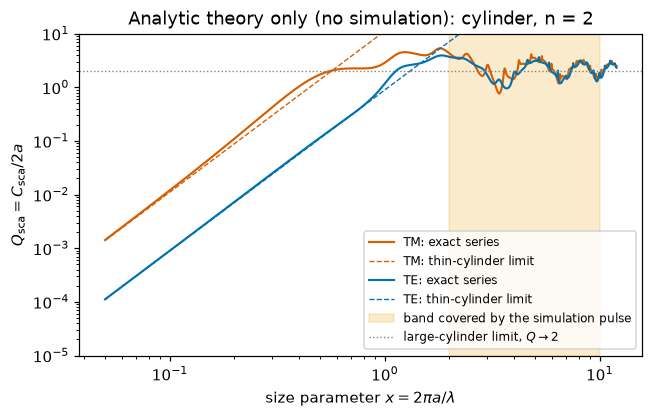

In [3]:
A_CYL = 1.0e-6  # cylinder radius [m]
N_CYL = 2.0  # refractive index (lossless)
X_MIN, X_MAX = 2.0, 10.0  # size-parameter band of the pulse
POLS = {"TM": "z", "TE": "y"}  # E_inc direction for propagation along +x
x_plot = np.geomspace(0.05, 12, 1500)

fig, ax = plt.subplots(figsize=(6.6, 3.8))
for pol, col in (("TM", "#D55E00"), ("TE", "#0072B2")):
    q_sca = cylinder_efficiencies(N_CYL, x_plot, pol)[1]
    ax.loglog(x_plot, q_sca, color=col, lw=1.4, label=f"{pol}: exact series")
    ax.loglog(x_plot, cylinder_rayleigh_efficiencies(N_CYL, x_plot, pol), "--",
              color=col, lw=0.9, label=f"{pol}: thin-cylinder limit")  # fmt: skip
ax.axvspan(X_MIN, X_MAX, color="#E69F00", alpha=0.2,
           label="band covered by the simulation pulse")  # fmt: skip
ax.axhline(2, color="0.5", lw=0.9, ls=":", label=r"large-cylinder limit, $Q \to 2$")
ax.set(
    xlabel=r"size parameter $x = 2\pi a/\lambda$",
    ylabel=r"$Q_\mathrm{sca} = C_\mathrm{sca}/2a$",
    ylim=(1e-5, 10),
    title=f"Analytic theory only (no simulation): cylinder, n = {N_CYL:g}",
)
ax.legend(fontsize=8, loc="lower right")
savefig(fig, "cylinder_theory.png")
plt.show()

## 2. The TF/SF source: equivalence principle on a grid

**The problem.** We want a plane wave to hit the cylinder and we want to
read off the scattered field alone. Imposing the plane-wave field on a
plane of the grid (a *hard* source) would also reflect the waves scattered
back onto that plane.

**The equivalence principle** (Oskooi & Johnson 2013, sec. 4.2.1 and their
fig. 4.1). The incident wave $\psi_\mathrm{inc} = (\mathbf E_\mathrm{inc},
\mathbf H_\mathrm{inc})$ solves the source-free Maxwell equations of the
background everywhere. Choose a closed surface $\partial\Omega$ and define
a new field equal to $\psi_\mathrm{inc}$ inside $\Omega$ and *zero*
outside. It satisfies Maxwell's equations everywhere except on
$\partial\Omega$, where it jumps, and a jump in a curl equation is a
surface current. The discontinuous field is therefore the exact field of
the surface currents (their eq. 4.4, $\hat n$ the unit normal pointing
*into* $\Omega$)

$$\mathbf J_s = \hat n \times \mathbf H_\mathrm{inc},\qquad
  \mathbf K_s = -\hat n \times \mathbf E_\mathrm{inc}.$$

These currents radiate the incident wave into $\Omega$ and nothing
outside. By linearity, a scatterer inside $\Omega$ does not change what the
currents radiate: inside we get the **total field** (incident +
scattered), outside only the **scattered field**, and the currents are
transparent to the scattered waves that cross them. This is the TF/SF
method, introduced for finite differences by Merewether, Fisher & Smith
(1980) and described in Taflove & Hagness (2005, ch. 5).

**By hand, with continuum fields.** The companion Meep notebook
(*Total-Field/Scattered-Field Technique with Meep FDTD*) builds exactly
this: electric and magnetic current sheets on the faces of a box, each with
the analytic plane-wave phase. On a grid the cancellation outside the box
is then only approximate, for two reasons:
(i) the analytic wave travels at $c$, the grid wave at the slightly
smaller, direction-dependent numerical phase velocity, so the sheets and
the wave they launch drift out of phase across the box; and
(ii) on a staggered grid $\mathbf E$ and $\mathbf H$ sit half a cell (and
half a time step) apart, so sheets referenced to the same plane do not
reproduce the discrete jump. The mismatch leaks a weak wave into the
scattered-field region, exactly where we measure.

**On the grid** (`wakis.TFSFSource`). Applying the same derivation to the
*discrete* curl operators gives the TF/SF update terms, and the incident
field must then solve the *discrete* equations (Oskooi & Johnson,
sec. 4.2.2). For axis-aligned incidence the incident wave is uniform
across the beam, so it is computed on a 1D auxiliary FIT line with the
grid's own cell lengths, time step and time levels; the 3D update is
corrected only on the edges straddling the box surface. Because the
auxiliary line obeys the same discrete equations, the incident field
cancels outside the box to **round-off**, at every frequency.

**How well does each construction cancel?** The TF/SF study
(`studies/tfsf/tfsf_study.py`) drives the same box in an empty domain in
four ways and measures the power leaking out of a closed box in the
scattered-field region, relative to the incident power on one face:

| construction | 10 cells/λ | 20 cells/λ | 56 cells/λ |
|---|---|---|---|
| `TFSFSource` (1D auxiliary FIT line) | 6e-32 | 8e-32 | 4e-32 (round-off) |
| face current sheets, values from the discrete auxiliary line | 6e-32 | 7e-32 | 4e-32 (round-off) |
| continuum sheets with exact half-cell E/H registration | 2.1e-3 | 9.6e-5 | 1.3e-6 (slope -4) |
| continuum sheets both referenced to the face plane (as in the hand-built Meep version) | 0.15 | 2.8e-2 | 3.0e-3 (slope -2) |

Two lessons. First, the second row shows that the TF/SF correction terms
*are* the equivalent currents $\mathbf J_s$, $\mathbf K_s$ of the
equivalence principle, evaluated with the discrete incident field: written
as current sheets they cancel to round-off as well. Second, with continuum
fields the leakage falls as $h^4$ when the half-cell staggering is
respected (only numerical dispersion is left), but only as $h^2$ when both
sheets sit on the face plane, and it is still 0.3 % of the power at 56
cells per wavelength. The discrete source costs about 1 % extra per time
step.

The sketch shows our layout; below it, the leakage maps of the study.

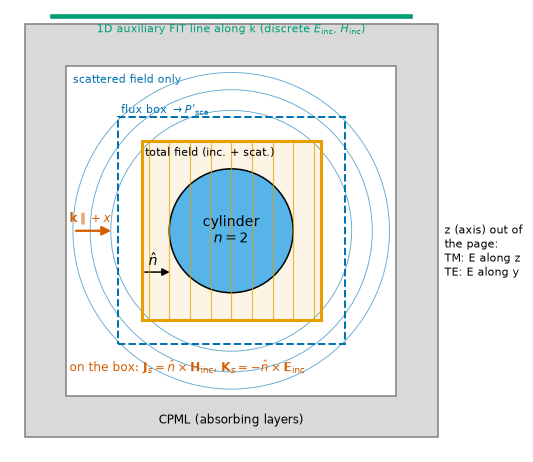

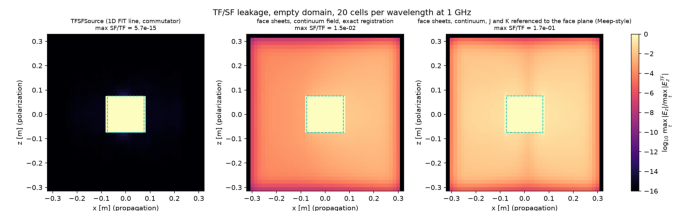

In [4]:
def draw_tfsf_diagram(ax):
    """Schematic x-y cut of the 2D TF/SF set-up (own drawing)."""
    from matplotlib.patches import Circle, FancyArrowPatch, Rectangle

    ax.set_xlim(-3.2, 3.6)
    ax.set_ylim(-3.2, 3.2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.add_patch(Rectangle((-3, -3), 6, 6, fc="0.85", ec="0.5"))
    ax.add_patch(Rectangle((-2.4, -2.4), 4.8, 4.8, fc="white", ec="0.5"))
    ax.text(0, -2.75, "CPML (absorbing layers)", ha="center", va="center", fontsize=8)
    for rad in (1.75, 2.05, 2.3):
        ax.add_patch(Circle((0, 0), rad, fill=False, ec="#0072B2", lw=0.6, alpha=0.6))
    ax.add_patch(Rectangle((-1.3, -1.3), 2.6, 2.6, fc="#E69F00", alpha=0.10, ec="none"))
    for xf in np.linspace(-1.2, 1.2, 9):
        ax.plot([xf, xf], [-1.3, 1.3], color="#E69F00", lw=0.8, alpha=0.7)
    ax.add_patch(Rectangle((-1.3, -1.3), 2.6, 2.6, fill=False, ec="#E69F00", lw=2))
    ax.add_patch(Circle((0, 0), 0.9, fc="#56B4E9", ec="k", lw=1))
    ax.text(0, 0, "cylinder\n$n=2$", ha="center", va="center", fontsize=9)
    ax.text(-1.25, 1.22, "total field (inc. + scat.)", fontsize=7.5, va="top")
    ax.text(-2.3, 2.15, "scattered field only", fontsize=7.5, color="#0072B2")
    ax.add_patch(
        Rectangle((-1.65, -1.65), 3.3, 3.3, fill=False, ec="#0072B2", lw=1.3, ls="--")
    )
    ax.text(-1.6, 1.7, r"flux box $\to P'_\mathrm{sca}$", fontsize=7.5, color="#0072B2")
    ax.add_patch(FancyArrowPatch((-1.3, -0.6), (-0.85, -0.6), arrowstyle="-|>",
                                 mutation_scale=10, color="k"))  # fmt: skip
    ax.text(-1.2, -0.5, r"$\hat n$", fontsize=9)
    ax.text(-2.35, -2.05, r"on the box: $\mathbf{J}_s=\hat n\times\mathbf{H}_\mathrm{inc}$, "
            r"$\mathbf{K}_s=-\hat n\times\mathbf{E}_\mathrm{inc}$",
            fontsize=8, color="#D55E00")  # fmt: skip
    ax.add_patch(FancyArrowPatch((-2.3, 0.0), (-1.7, 0.0), arrowstyle="-|>",
                                 mutation_scale=12, color="#D55E00", lw=1.5))  # fmt: skip
    ax.text(-2.35, 0.12, r"$\mathbf{k}\parallel+x$", fontsize=8, color="#D55E00")
    ax.plot([-2.6, 2.6], [3.12, 3.12], color="#009E73", lw=3)
    ax.text(0, 2.88, "1D auxiliary FIT line along k (discrete $E_\\mathrm{inc}$, "
            "$H_\\mathrm{inc}$)", ha="center", fontsize=7.5, color="#009E73")  # fmt: skip
    ax.text(3.1, -0.3, "z (axis) out of\nthe page:\nTM: E along z\nTE: E along y",
            fontsize=7.5, va="center")  # fmt: skip


fig, ax = plt.subplots(figsize=(5.8, 5.2))
draw_tfsf_diagram(ax)
savefig(fig, "tfsf_diagram.png")
plt.show()

for name in ("tfsf_leakage_map.png",):
    png = HERE.parents[0].parent / "studies" / "tfsf" / name
    png = png if png.exists() else FIG_DIR / name
    if png.exists():
        show_png(png, figsize=(12, 4))

## 3. Geometry: a 2D problem in a 3D solver

Wakis is a 3D solver. A 2D problem (fields independent of $z$) is a slab
a few cells thick along $z$ with **periodic** boundaries: a field that is
uniform along $z$ is an exact solution of the periodic problem. We use
$N_z = 4$ cells (one would do for the update; four let the flux box have
$z$ faces on interior nodes, see below) and CPML in $x$ and $y$.

The cylinder is a closed triangulated surface (PyVista &rarr; STL, as CAD
geometry would arrive), taller than the slab so that its caps lie outside
the domain. Its facets are $2\pi a/720 \approx 9$ nm long, far below the
cell size.

**Layout.** All boxes are placed on grid nodes with a few cells between
neighbours. The TF/SF box spans the whole period along $z$ (no $z$ faces).

| region | half-width | purpose |
|---|---|---|
| cylinder | 1.0 µm | scatterer, $\varepsilon_r = 4$ |
| inner flux box | $a$ + 2 cells | total field: $-P'_\mathrm{abs}$ (0 here) |
| TF/SF box | $\approx$ 1.25 µm | plane wave inside, scattered field outside |
| scattered flux box | TF + $\approx$ 0.2 µm | $P'_\mathrm{sca}$ |
| CPML start | flux + $\approx$ 0.6 µm | 10 absorbing cells |

In [5]:
N_PML = 10
NZ = 4  # cells along the periodic cylinder axis


def layout(resolution_per_um):
    """Grid and box positions (cell indices from the centre) for a resolution."""
    dx = 1e-6 / resolution_per_um
    i_a = int(np.ceil(A_CYL / dx - 1e-9))
    i_in = i_a + 2  # inner flux box: clear of the averaged interface edges
    i_tf = max(i_in + 2, int(round(1.25e-6 / dx)))
    i_flux = i_tf + max(2, int(round(0.2e-6 / dx)))
    i_pml = i_flux + max(6, int(round(0.6e-6 / dx)))
    n_half = i_pml + N_PML
    return dict(
        dx=dx, n_cells=2 * n_half, half=n_half * dx,
        inner=i_in * dx, tf=i_tf * dx, flux=i_flux * dx, pml=i_pml * dx,
    )  # fmt: skip


STL_FILE = str(HERE / "cylinder.stl")
cylinder = pv.Cylinder(radius=A_CYL, height=10e-6, direction=(0, 0, 1),
                       resolution=720, capping=True).triangulate()  # fmt: skip
cylinder.save(STL_FILE)


def make_grid(resolution_per_um, conformal, half_cells=None):
    """GridFIT3D: 2D slab with the cylinder; conformal in staircase/all/tensor."""
    lay = layout(resolution_per_um)
    h, n = lay["half"], lay["n_cells"]
    if half_cells is not None:
        h, n = half_cells * lay["dx"], 2 * half_cells
    hz = NZ / 2 * lay["dx"]
    return wakis.GridFIT3D(
        -h, h, -h, h, -hz, hz, n, n, NZ,
        stl_solids={"cylinder": STL_FILE},
        stl_materials={"cylinder": [N_CYL**2, 1.0]},  # [eps_r, mu_r]
        conformal=False if conformal == "staircase" else conformal,
        verbose=0,
    ), lay  # fmt: skip


def make_solver(grid, use_gpu=False):
    return wakis.SolverFIT3D(
        grid,
        bc_low=["cpml", "cpml", "periodic"],
        bc_high=["cpml", "cpml", "periodic"],
        n_pml=N_PML,
        use_stl=True,
        use_gpu=use_gpu,
        verbose=0,
    )

The set-up in 3D with `wakis.visualize.plot_scene` (the slab is thin along
$z$; the cylinder is cut to the slab for the picture).

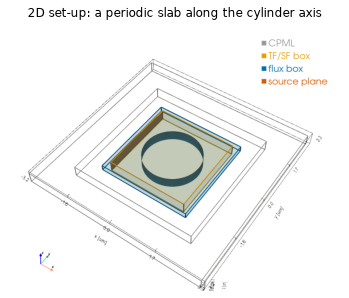

In [6]:
grid_view, lay_view = make_grid(10, "staircase")
hz = NZ / 2 * lay_view["dx"]
slab = (
    -lay_view["half"],
    lay_view["half"],
    -lay_view["half"],
    lay_view["half"],
    -hz,
    hz,
)
pl = wv.plot_scene(
    grid_view,
    boxes={
        "tfsf": (
            -lay_view["tf"],
            lay_view["tf"],
            -lay_view["tf"],
            lay_view["tf"],
            -hz,
            hz,
        ),
        "flux": (
            -lay_view["flux"],
            lay_view["flux"],
            -lay_view["flux"],
            lay_view["flux"],
            -hz / 2,
            hz / 2,
        ),
    },  # fmt: skip
    planes={"source": ((-lay_view["tf"], 0, 0), "x", (2 * lay_view["tf"], 2 * hz))},
    cpml=(
        slab,
        (-lay_view["pml"], lay_view["pml"], -lay_view["pml"], lay_view["pml"], -hz, hz),
    ),  # fmt: skip
    solids=False,
    elevation=50,
)
pl.add_mesh(cylinder.clip_box([-3e-6, 3e-6, -3e-6, 3e-6, -hz, hz], invert=False)
            .scale(1e6, inplace=False), color="#56B4E9")  # fmt: skip
wv.save_plotter(pl, str(FIG_DIR / "scene.png"))
show_png(FIG_DIR / "scene.png", "2D set-up: a periodic slab along the cylinder axis")

## 4. The mesh the solver sees: staircase versus conformal

FIT stores one permittivity per primary edge. In 2D TM ($E_z$) the
relevant edges are the $z$ edges, one per node of the $xy$ plane; in TE
the in-plane $x$ and $y$ edges. Three material models:

* **staircase** (`conformal=False`): each edge takes the material at its
  location, so the circle becomes a staircase of whole cells;
* **conformal** (`conformal='all'`): at an interface with normal $\hat n$
  cutting an edge's dual cell with fill fraction $f$, the physically
  right inverse permittivity is the tensor
  $T = \langle\varepsilon^{-1}\rangle\,\hat n\hat n^T +
  (I - \hat n\hat n^T)/\langle\varepsilon\rangle$ (Kottke, Farjadpour &
  Johnson 2008): field components tangential to the surface see the
  average permittivity, the normal component the average inverse
  permittivity. Mode `'all'` keeps the diagonal entry of $T$ for each edge
  (fill fractions from the STL by subcell sampling), placing the interface
  to a fraction of a cell;
* **tensor** (`conformal='tensor'`): also applies the off-diagonal
  couplings between the $x$ and $y$ edges, which matter when E crosses a
  tilted interface (TE). For TM, E is tangential everywhere on the
  cylinder surface and `'tensor'` reduces to `'all'`.

First PyVista (each edge drawn as its dual cell, the true circle in red),
then a matplotlib view of the in-plane edges for TE.

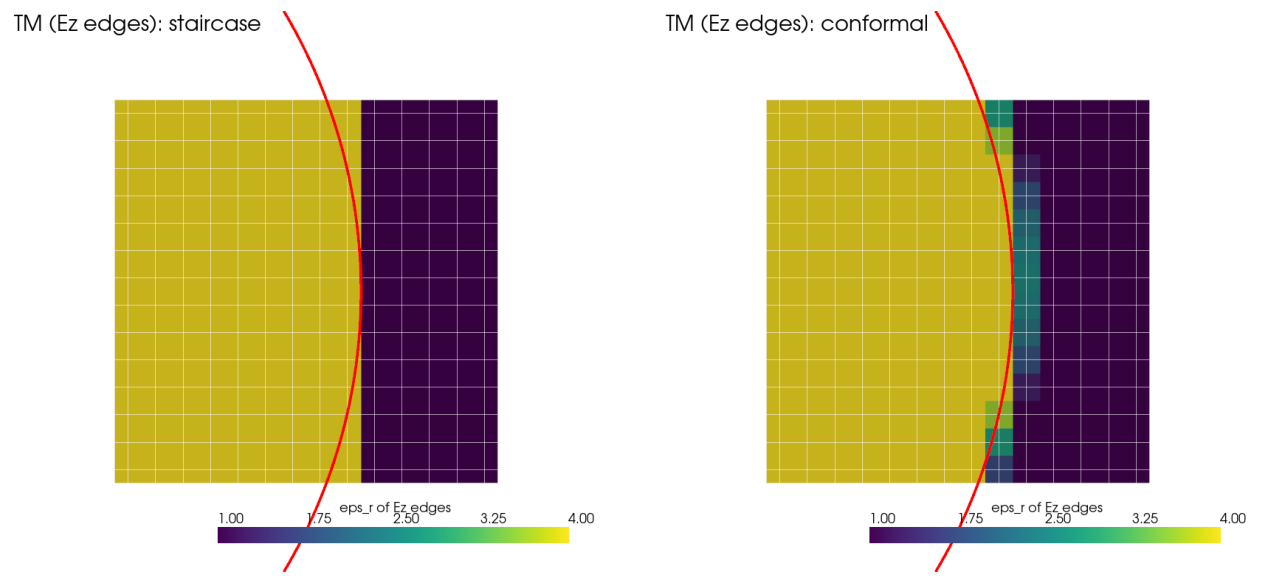

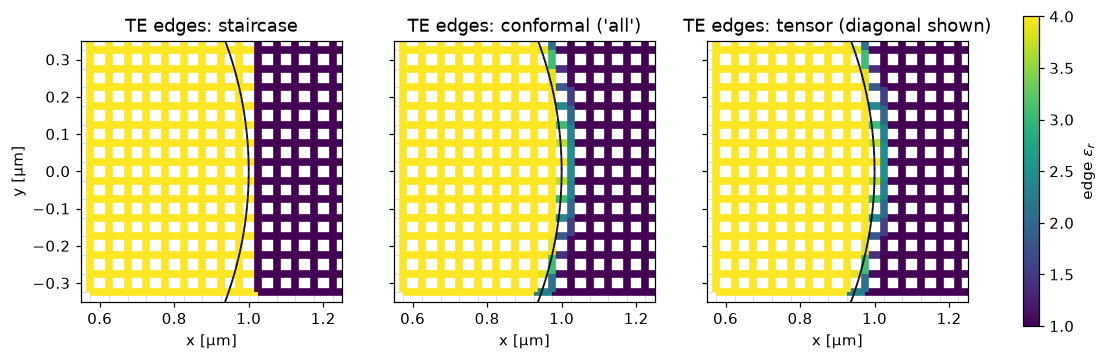

In [7]:
window = (0.55e-6, 1.25e-6, -0.35e-6, 0.35e-6)
pngs = []
for model in ("staircase", "all"):
    g, _ = make_grid(20, model, half_cells=26)
    s = wakis.SolverFIT3D(g, bc_low=["pec", "pec", "periodic"],
                          bc_high=["pec", "pec", "periodic"], use_stl=True, verbose=0)  # fmt: skip
    pl = wv.plot_material_plane(s, component="z", axis="z", position=0.0,
                                window=window, surfaces=[cylinder], vmax=N_CYL**2,
                                title=f"TM (Ez edges): {'conformal' if model == 'all' else model}")  # fmt: skip
    pngs.append(wv.save_plotter(pl, str(FIG_DIR / f"mesh_tm_{model}.png")))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, img in zip(axes, pngs):
    ax.imshow(img)
    ax.axis("off")
fig.tight_layout()
savefig(fig, "mesh_tm_pyvista.png")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, model in zip(axes, ["staircase", "all", "tensor"]):
    g, _ = make_grid(20, model, half_cells=26)
    s = wakis.SolverFIT3D(g, bc_low=["pec", "pec", "periodic"],
                          bc_high=["pec", "pec", "periodic"], use_stl=True, verbose=0)  # fmt: skip
    lc = wv.plot_material_slice(
        s, axis="z", position=0.0, window=window, surface="cylinder", ax=ax,
        vmin=1, vmax=N_CYL**2, colorbar=False,
        title={"staircase": "TE edges: staircase", "all": "TE edges: conformal ('all')",
               "tensor": "TE edges: tensor (diagonal shown)"}[model],
    )  # fmt: skip
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.colorbar(lc, ax=axes, label=r"edge $\varepsilon_r$", shrink=0.85)
savefig(fig, "mesh_te_staircase_vs_conformal.png")
plt.show()

**How big is the cylinder the solver sees?** For TM the polarizable area
is $\sum (\varepsilon_{r,e} - 1)/(\varepsilon_r - 1)\, \Delta x\Delta y$
over the $E_z$ edges. The staircase cylinder comes out too large, by
9.5 % at 10 cells/µm down to 1.8 % at 60 cells/µm: every node inside the
circle carries a whole dual cell of dielectric, which moves the effective
surface outwards by about half a cell, a first-order error
($\delta A/A \approx \Delta x / a$). The conformal area is exact to the
printed digits. A cylinder 3.6 % too large in area (30 cells/µm) has a
radius 1.8 % too large, which shifts every resonance by 1.8 % in $x$:
that is the staircase error we will see in section 10.

In [8]:
print(" cells/µm   staircase area/πa²   conformal area/πa²")
for res in (10, 15, 20, 30, 40, 60):
    row = []
    for model in ("staircase", "all"):
        half = int(np.ceil(1.15e-6 * res / 1e-6))
        g, lay = make_grid(res, model, half_cells=half)
        s = wakis.SolverFIT3D(g, bc_low=["pec", "pec", "periodic"],
                              bc_high=["pec", "pec", "periodic"], use_stl=True,
                              verbose=0)  # fmt: skip
        eps, _ = wv.edge_permittivity(s, "z", "z", 0.0)
        fill = (eps[np.isfinite(eps)] - 1) / (N_CYL**2 - 1)
        row.append(fill.sum() * lay["dx"] ** 2 / (np.pi * A_CYL**2))
    print(f"{res:>8}   {row[0]:18.4f}   {row[1]:18.4f}")

 cells/µm   staircase area/πa²   conformal area/πa²


      10               1.0950               1.0000


      15               1.0695               1.0000


      20               1.0536               1.0000


      30               1.0356               1.0000


      40               1.0289               1.0000


      60               1.0182               1.0000


## 5. Preflight: estimate memory and run time *before* running

A 3D electromagnetic problem grows as (cells per wavelength)$^3$ in memory
and (cells per wavelength)$^4$ in work; a 2D one as the square and the
cube. Either way, `wakis.estimate.estimate` predicts the peak memory and
run time from coefficients measured on our benchmark machines, and
`preflight` checks them against the target machine (raising `MemoryError`
when the run does not fit). Inputs: cells, time steps, backend, CPML,
conformal mode with the number of interface cells, and the DFT monitors.
**Make this a habit**: a 3D run at twice the resolution needs 8x the memory.

In [9]:
T_RUN = (
    ARGS.t_run or 600
) * 1e-15  # max simulated time [s]; stops earlier once fields decay
N_FREQ = 81
X_SIM = np.linspace(X_MIN, X_MAX, N_FREQ)
FREQS = X_SIM * c0 / (2 * np.pi * A_CYL)  # [Hz]
F_CENTER = 0.5 * (FREQS[0] + FREQS[-1])
F_WIDTH = 0.25 * (FREQS[-1] - FREQS[0])  # band edges at 2 sigma


def plan(resolution_per_um, conformal, use_gpu, machine):
    lay = layout(resolution_per_um)
    n = lay["n_cells"]
    dt = 0.5 * lay["dx"] / (c0 * np.sqrt(3))  # CFL 0.5 on a cubic grid
    steps = int(T_RUN / dt)
    n_flux = 4 * (2 * lay["flux"] / lay["dx"]) * 3  # 4 faces x 3 z nodes
    est = estimate(
        (n, n, NZ), steps,
        backend="gpu" if use_gpu else "cpu", cpml=True,
        conformal=False if conformal == "staircase" else conformal,
        interface_cells=int(2 * 2 * np.pi * A_CYL / lay["dx"] * NZ),
        monitors=[(N_FREQ, n_flux, 4), (N_FREQ, n_flux, 4), (3, n * n, 1)],
    )  # fmt: skip
    return lay, steps, est, preflight(est, machine, raise_error=False)


# Target machine: a name from wakis.estimate.MACHINES or a dict (bytes)
if IN_COLAB:
    MACHINE = dict(ram=12e9, gpu=15e9 if USE_GPU else 0)  # Colab runtime
elif USE_GPU:
    MACHINE = "g2-standard-16"  # 64 GB RAM, NVIDIA L4 24 GB
else:
    MACHINE = os.environ.get("WAKIS_MACHINE", "laptop")  # 2 GB memguard cap
for res in (20, 40, 60, 120):
    lay, steps, est, problems = plan(res, CONFORMAL, USE_GPU, MACHINE)
    print(f"{res:>4} cells/µm: {lay['n_cells']}²x{NZ} = {est.cells / 1e6:5.3f} Mcells, "
          f"<= {steps} steps, host {est.host_bytes / 1e9:4.2f} GB, "
          f"~{est.seconds / 60:5.1f} min per polarization: "
          f"{'fits ' + str(MACHINE) if not problems else 'DOES NOT FIT: ' + '; '.join(problems)}")  # fmt: skip

lay, steps, est, problems = plan(RESOLUTION, CONFORMAL, USE_GPU, MACHINE)
print("\nThis run (per polarization):\n", est)
if problems:
    raise MemoryError("; ".join(problems))

  20 cells/µm: 102²x4 = 0.042 Mcells, <= 12462 steps, host 0.81 GB, ~  1.5 min per polarization: fits g2-standard-16
  40 cells/µm: 184²x4 = 0.135 Mcells, <= 24924 steps, host 1.00 GB, ~  3.0 min per polarization: fits g2-standard-16
  60 cells/µm: 266²x4 = 0.283 Mcells, <= 37386 steps, host 1.31 GB, ~  4.5 min per polarization: fits g2-standard-16
 120 cells/µm: 512²x4 = 1.049 Mcells, <= 74772 steps, host 2.87 GB, ~  8.9 min per polarization: fits g2-standard-16

This run (per polarization):
 cells: 283,024
peak host RAM: 1.31 GB
peak GPU memory: 0.34 GB
run time: 4.5 min (setup 2 s, 7.10 ms/step)
  solver (host): 0.853 GB
  conformal (host): 0.069 GB
  monitors: 0.025 GB
  dispersive: 0.000 GB
  conformal setup peak (host): 1.045 GB


## 6. Sources, monitors and the per-length normalization

* **Time signal**: `GaussianSource` centred at $x = 6$, spectral width
  covering $x = 2\dots10$ (vacuum wavelengths 3.1 to 0.63 µm).
* **Source**: `TFSFSource(direction="+x", polarization="z")` for TM and
  `polarization="y"` for TE, amplitude 1 V/m. `size=(.., .., None)`: the box
  spans the periodic $z$ extent.
* **Monitors**: a `FluxMonitor` box in the scattered-field region and one
  hugging the cylinder inside the total-field region (net inward flux =
  absorbed power, zero here: a check that can fail), a `DFTMonitor` on the
  $z = 0$ plane at three size parameters, and a `SliceRecorder` for a movie.

**Normalization (check it!).** The flux box spans $z \in [-\Delta, \Delta]$,
so its side faces have height $L_z = 2\Delta$ (the trapezoid rule gives
the samples on the $z = \pm\Delta$ edges half weight; the $z$ faces carry
no flux since $S_z = 0$ for a $z$-invariant field). The monitor returns
the power through those faces, $P'_\mathrm{sca} L_z$, and the source
reports the incident flux per unit area $\Phi_\mathrm{inc}$ with the same
DFT convention, so

$$C_\mathrm{sca}(x) = \frac{\Phi_\mathrm{sca}}{L_z\,\Phi_\mathrm{inc}},
  \qquad Q_\mathrm{sca} = \frac{C_\mathrm{sca}}{2a}.$$

The pulse spectrum cancels in the ratio.

In [10]:
X_SNAP = np.array([3.0, 6.0, 9.0])  # size parameters of the field maps
F_SNAP = X_SNAP * c0 / (2 * np.pi * A_CYL)


def run_cylinder(resolution_per_um, conformal, pol, use_gpu=False, extras=True,
                 movie=True, energy_decay=1e-7, scatterer=True, verbose=0):  # fmt: skip
    """Build, run and post-process one 2D simulation; returns a dict."""
    t0 = time.time()
    grid, lay = make_grid(resolution_per_um, conformal)
    if not scatterer:  # empty domain: same grid, cylinder material = vacuum
        grid.stl_materials["cylinder"] = [1.0, 1.0, 0.0]
    solver = make_solver(grid, use_gpu)
    t_setup = time.time() - t0
    dx = lay["dx"]
    pulse = GaussianSource(frequency=F_CENTER, fwidth=F_WIDTH)
    src = wakis.TFSFSource(
        pulse, center=(0, 0, 0), size=(2 * lay["tf"], 2 * lay["tf"], None),
        direction="+x", polarization=POLS[pol], amplitude=1.0,
    )  # fmt: skip
    lz = 2 * dx  # z extent of the flux boxes
    scat = wakis.FluxMonitor(FREQS, size=(2 * lay["flux"], 2 * lay["flux"], lz))
    inner = wakis.FluxMonitor(FREQS, size=(2 * lay["inner"], 2 * lay["inner"], lz))
    monitors = [scat, inner]
    out = dict(grid=grid, solver=solver, src=src, lay=lay, pol=pol)
    field = "Ez" if pol == "TM" else "Hz"  # the field component along the axis
    if extras:
        span = 2 * lay["pml"]
        plane = wakis.DFTMonitor(F_SNAP, components=(field,), size=(span, span, 0.0))
        monitors.append(plane)
        out["plane"] = plane
        if movie:
            rec = wv.SliceRecorder(field, axis="z", position=0.0,
                                   every=max(1, int(160e-15 / solver.dt / 120)),
                                   t_stop=160e-15)  # fmt: skip
            monitors.append(rec)
            out["movie"] = rec
    n_max = int(T_RUN / solver.dt)
    solver.verbose = verbose
    t1 = time.time()
    solver.emsolve(n_max, source=[src], monitors=monitors,
                   stop_when_energy_decayed=(energy_decay, 50))  # fmt: skip
    t_run = time.time() - t1
    phi_inc = src.incident_flux_density(FREQS)
    width = 2 * A_CYL
    out.update(
        x=X_SIM, field=field,
        q_sca=scat.get_flux() / (lz * phi_inc) / width,
        q_abs=-inner.get_flux() / (lz * phi_inc) / width,
        steps=solver.Nt, dt=solver.dt, cells=int(grid.Nx * grid.Ny * grid.Nz),
        setup_s=t_setup, run_s=t_run, resolution=resolution_per_um,
        conformal=conformal, gpu=gpu_name() if use_gpu else None,
        stopped_early=bool(solver.Nt < n_max),
        leak=scat.get_flux() / (phi_inc * 2 * lay["flux"] * lz),
    )  # fmt: skip
    return out


def summary(res):
    """JSON-serializable summary of a run (no field data)."""
    q_ref = cylinder_efficiencies(N_CYL, res["x"], res["pol"])[1]
    err = res["q_sca"] - q_ref
    return dict(
        resolution_per_um=res["resolution"], conformal=res["conformal"],
        pol=res["pol"], cells=res["cells"], steps=int(res["steps"]),
        dt_s=res["dt"], setup_s=res["setup_s"], run_s=res["run_s"],
        gpu=res["gpu"], stopped_early=res["stopped_early"], t_run_s=T_RUN,
        x=[round(v, 6) for v in res["x"]],
        q_sca=[round(float(v), 7) for v in res["q_sca"]],
        q_abs=[round(float(v), 7) for v in res["q_abs"]],
        q_ref=[round(float(v), 7) for v in q_ref],
        rel_rms_error=float(np.sqrt(np.mean(err**2) / np.mean(q_ref**2))),
        max_abs_error=float(np.max(np.abs(err))),
        max_abs_q_abs=float(np.max(np.abs(res["q_abs"]))),
        cells_per_wavelength_in_cylinder_at_xmax=float(
            2 * np.pi * A_CYL / X_MAX / N_CYL / layout(res["resolution"])["dx"]
        ),
    )  # fmt: skip


if ARGS.arm:  # study mode: one run, JSON out, no figures
    pol = ARGS.pol or "TM"
    res = run_cylinder(RESOLUTION, CONFORMAL, pol, USE_GPU, extras=False)
    info = summary(res)
    out_path = Path(ARGS.out or f"cyl_{RESOLUTION:g}_{CONFORMAL}_{pol}.json")
    out_path.write_text(json.dumps(info, indent=1))
    print(f"wrote {out_path}: rel. RMS error {info['rel_rms_error']:.4f}, "
          f"{info['run_s']:.0f} s run, {info['steps']} steps")  # fmt: skip
    sys.exit(0)

## 7. Check the source, then run both polarizations

**First, check the source in an empty domain.** With no cylinder, the flux
out of the scattered-field box must vanish: anything left is leakage of
the incident wave, normalized here by the incident power through one face.

In [11]:
empty = run_cylinder(RESOLUTION, CONFORMAL, "TM", USE_GPU, extras=False,
                     scatterer=False)  # fmt: skip
print(f"empty domain, TM: max |leaked power| / incident power on a face = "
      f"{np.max(np.abs(empty['leak'])):.1e}")  # fmt: skip
del empty

empty domain, TM: max |leaked power| / incident power on a face = 4.2e-16


**Now the two polarizations.** They are independent runs, and in a script
they could run in parallel processes (see `tutorials/study.py`).

In [12]:
runs = {}
for pol in ("TM", "TE"):
    runs[pol] = run_cylinder(RESOLUTION, CONFORMAL, pol, USE_GPU, extras=True,
                             movie=not ARGS.no_movie)  # fmt: skip
    info = summary(runs[pol])
    print(f"{pol}: {info['cells'] / 1e3:.0f} kcells, {info['steps']} steps "
          f"({'energy decayed' if info['stopped_early'] else 'full window'}), "
          f"setup {info['setup_s']:.1f} s, run {info['run_s']:.1f} s on "
          f"{info['gpu'] or 'CPU'} (predicted {est.seconds:.0f} s); "
          f"rel. RMS error {info['rel_rms_error']:.2%}")  # fmt: skip
DATA_DIR.mkdir(exist_ok=True)
(DATA_DIR / f"run_{'full' if FULL else 'quick'}.json").write_text(
    json.dumps({p: summary(r) for p, r in runs.items()}, indent=1)
)

TM: 285 kcells, 37569 steps (full window), setup 2.6 s, run 451.9 s on NVIDIA L4 (predicted 267 s); rel. RMS error 1.86%


TE: 285 kcells, 37569 steps (full window), setup 2.6 s, run 450.5 s on NVIDIA L4 (predicted 267 s); rel. RMS error 2.21%


9215

## 8. Fields: total inside, scattered outside

The DFT plane monitor gives the complex field at three size parameters:
$E_z$ for TM, $H_z$ for TE (the component along the axis, a scalar in
2D), normalized by the incident field at the entry plane. Inside the
orange TF/SF box we see the total field: the incident wave focused by the
cylinder, which acts as a lens (the bright spot on the shadow side is a
"photonic nanojet" at larger $x$). Outside the box only the scattered
field remains; the log-scale maps show the incident plane wave stopping
at the box faces.

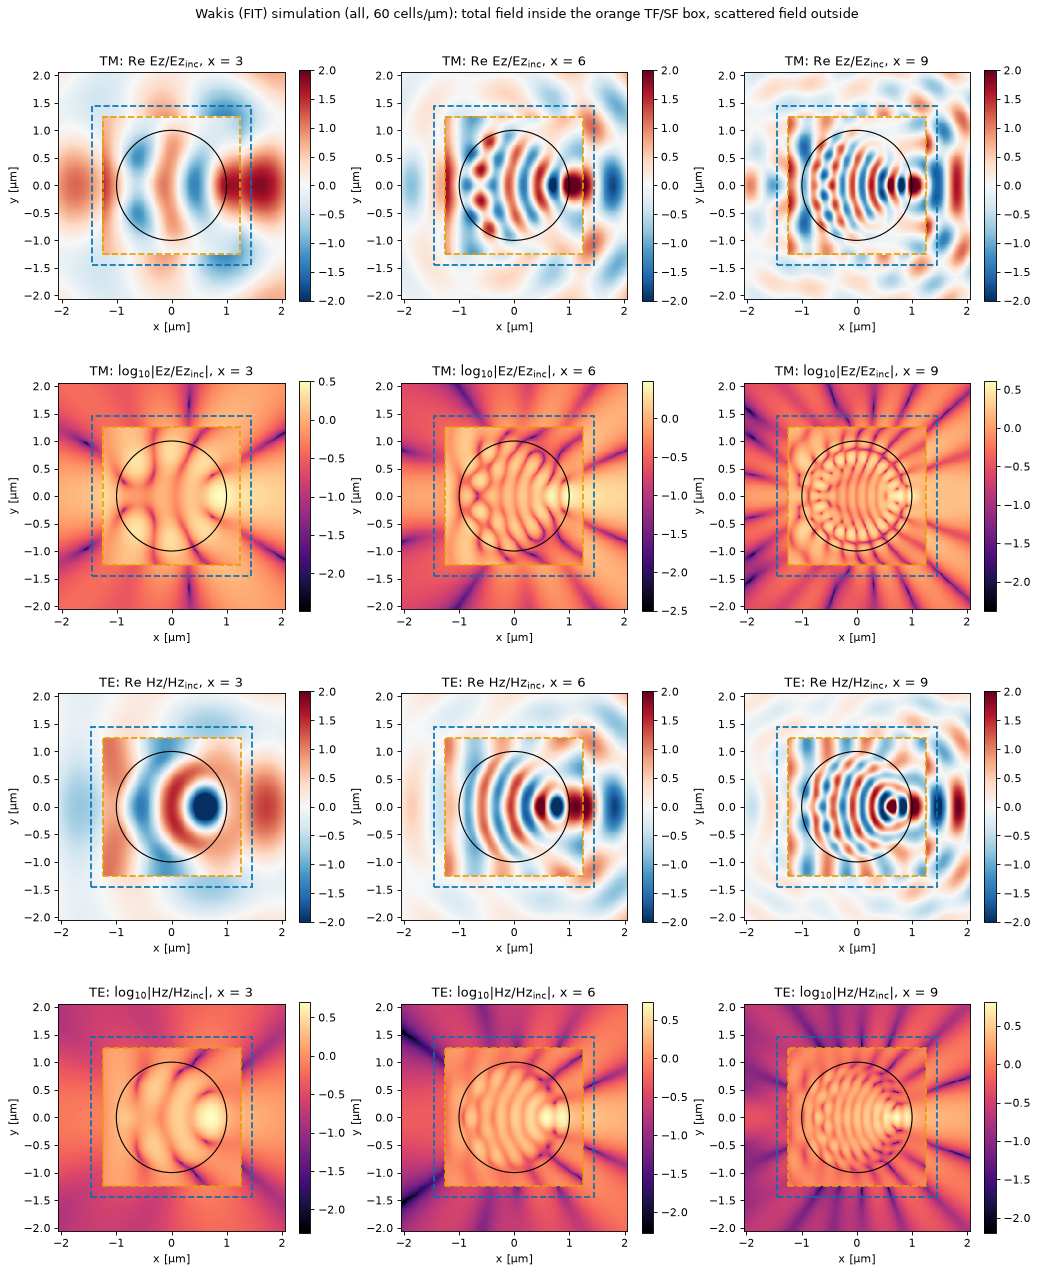

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(13, 16), dpi=80)
for r, pol in enumerate(("TM", "TE")):
    run = runs[pol]
    boxes = {"tfsf": run["src"].box_bounds(),
             "flux": wv.box_bounds((0, 0, 0), (2 * run["lay"]["flux"],) * 3)}  # fmt: skip
    E_inc, H_inc = run["src"].incident_fields(F_SNAP)
    ref = E_inc if pol == "TM" else H_inc
    values, co = wv.field_slice(run["plane"], "z", 0.0, run["field"])
    for j, xs in enumerate(X_SNAP):
        f = values[j] / ref[j]  # relative to the incident wave at the entry plane
        lab = f"{run['field']}/{run['field']}" + r"$_\mathrm{inc}$"
        wv.plot_field_slice(f, co, kind="real", ax=axes[2 * r, j], boxes=boxes,
                            axis="z", surface=((0, 0, 0), A_CYL), vmax=2.0,
                            title=f"{pol}: Re {lab}, x = {xs:g}")  # fmt: skip
        wv.plot_field_slice(f, co, kind="log", ax=axes[2 * r + 1, j], boxes=boxes,
                            axis="z", surface=((0, 0, 0), A_CYL), log_floor=1e-3,
                            title=f"{pol}: log$_{{10}}$|{lab}|, x = {xs:g}")  # fmt: skip
fig.suptitle(
    f"{wv.SIM_LABEL} simulation ({CONFORMAL}, {RESOLUTION:g} cells/µm): "
    "total field inside the orange TF/SF box, scattered field outside",
    y=1.0,
)
fig.tight_layout()
savefig(fig, "fields_xy.png", dpi=80)
plt.show()

The same fields in PyVista: the TM field at $x = 6$ as a relief (height
and colour = Re $E_z$), and the TE field flat.

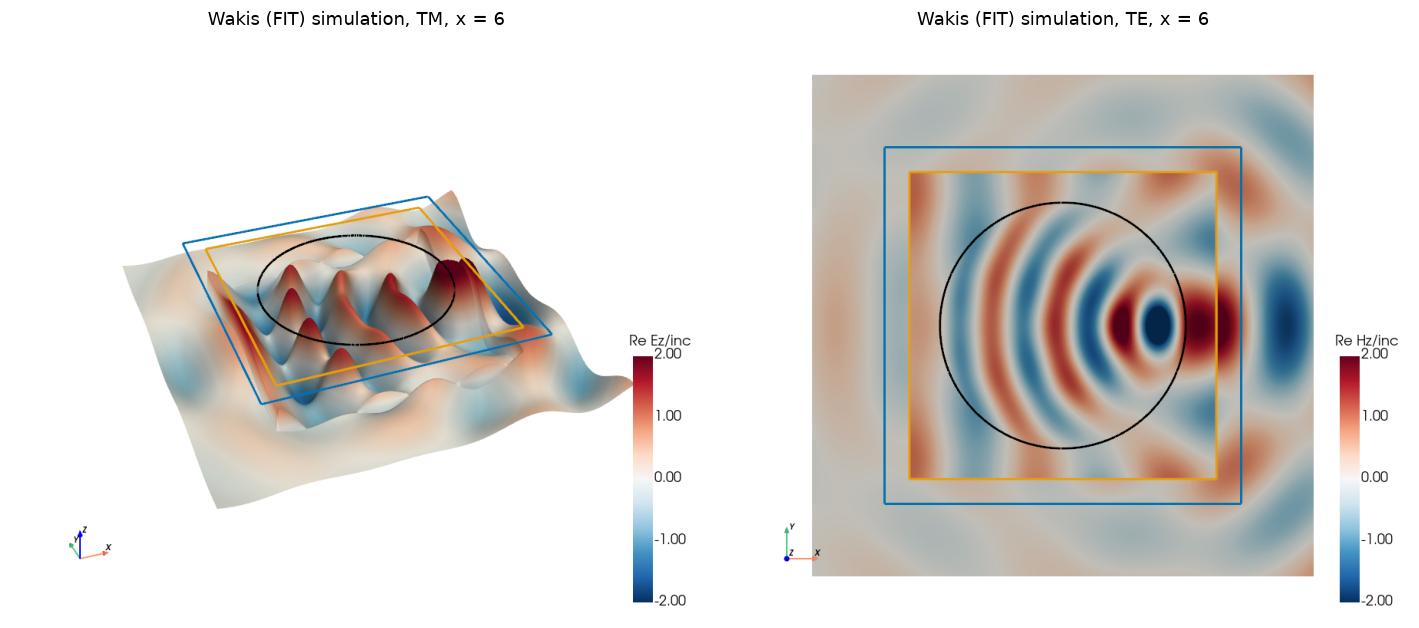

In [14]:
pngs = []
for pol, warp in (("TM", 0.12), ("TE", 0.0)):
    run = runs[pol]
    E_inc, H_inc = run["src"].incident_fields(F_SNAP[1:2])
    ref = (E_inc if pol == "TM" else H_inc)[0]
    values, co = wv.field_slice(run["plane"], "z", 0.0, run["field"])
    boxes = {"tfsf": run["src"].box_bounds(),
             "flux": wv.box_bounds((0, 0, 0), (2 * run["lay"]["flux"],) * 3)}  # fmt: skip
    pl = wv.plot_field_plane(values[1] / ref, co, axis="z", kind="real", vmax=2.0,
                             surfaces=[cylinder], boxes=boxes, warp=warp,
                             scalar_label=f"Re {run['field']}/inc")  # fmt: skip
    pngs.append(wv.save_plotter(pl, str(FIG_DIR / f"field_pyvista_{pol}.png")))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, img, pol in zip(axes, pngs, ("TM", "TE")):
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"{wv.SIM_LABEL} simulation, {pol}, x = {X_SNAP[1]:g}")
fig.tight_layout()
savefig(fig, "fields_pyvista.png")
plt.show()

And in time: $E_z$ (TM) as the pulse sweeps through the box. The incident
pulse appears at the left face, crosses the box and vanishes at the right
face; the cylinder's scattered wavelets leave the box in all directions
and are absorbed by the CPML.

movie: /home/erikshipton/tut01/tutorials/03_diffraction_and_scattering/03-04_mie_cylinder/figures/cylinder_movie.gif 0.84 MB


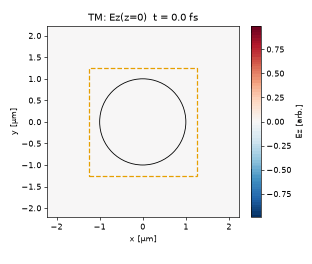

In [15]:
if "movie" in runs["TM"]:
    run = runs["TM"]
    boxes = {"tfsf": run["src"].box_bounds()}
    gif = wv.save_animation(
        run["movie"], str(FIG_DIR / "cylinder_movie.gif"), boxes=boxes,
        surface=((0, 0, 0), A_CYL), max_frames=60, fps=10, dpi=60,
        title="TM: Ez(z=0)",
    )  # fmt: skip
    print("movie:", gif, f"{os.path.getsize(gif) / 1e6:.2f} MB")
    if IN_NOTEBOOK:
        from IPython.display import Image, display

        display(Image(filename=gif))

## 9. $Q_\mathrm{sca}(x)$ versus the exact series

Simulated $Q_\mathrm{sca}$ (markers) for both polarizations against the
series (line), their difference, and $Q_\mathrm{abs}$ from the inner box.
For a lossless cylinder $Q_\mathrm{abs}$ must vanish. It does, except for
isolated spikes at the sharpest resonances. Those are not absorption: the
time integral of the net inward flux equals the energy still stored inside
the box when the run stops, and a resonance with $Q \sim 10^3$ is still
ringing at the end of the window. Its stored energy shows up as a narrow
spike of width $\sim 1/T$ in the flux spectrum, which grows with the window
length $T$ and does not shrink with resolution (the study measures it).
The same truncation affects $Q_\mathrm{sca}$ at those few frequencies.
The 20 cells/µm quick run is deliberately under-resolved at the short-
wavelength end: about 6 cells per wavelength inside the cylinder at
$x = 10$, so the resonances there are shifted.

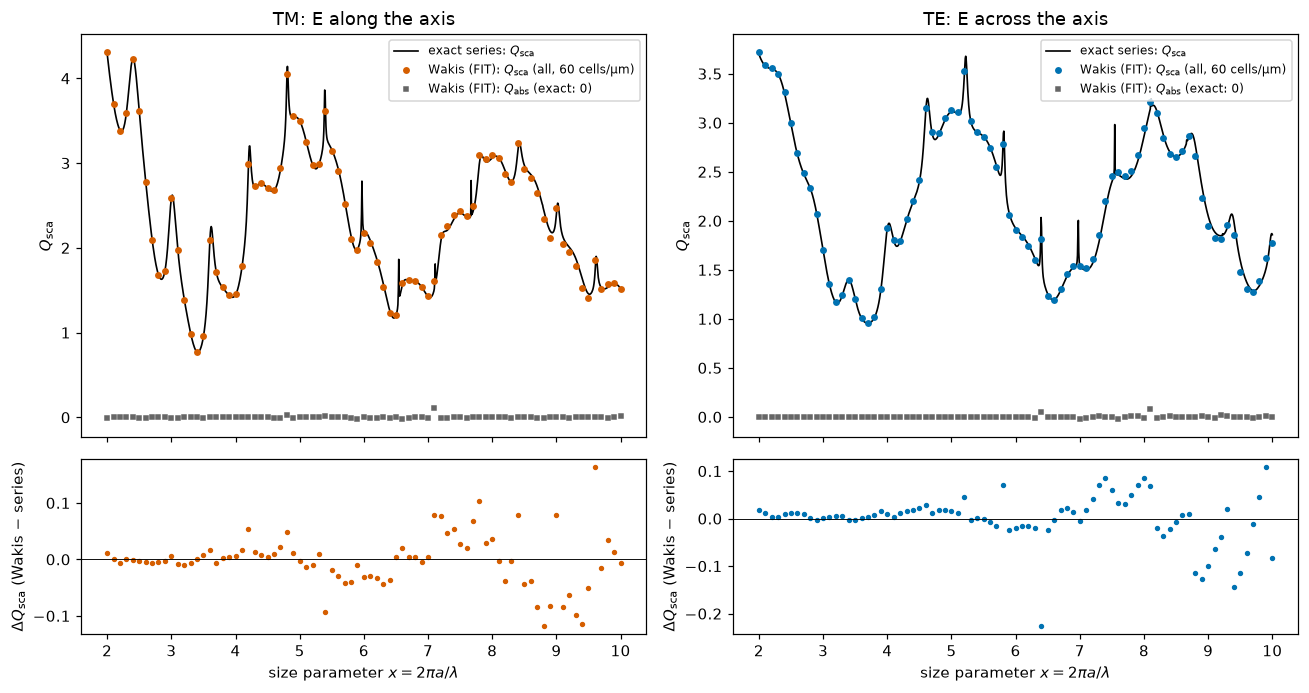

TM: relative RMS error 1.86%, max |ΔQ| 0.163, max |Q_abs| 1.1e-01
TE: relative RMS error 2.21%, max |ΔQ| 0.226, max |Q_abs| 8.1e-02


In [16]:
x_fine = np.linspace(X_MIN, X_MAX, 1200)
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True,
                         gridspec_kw=dict(height_ratios=[3, 1.3]))  # fmt: skip
for k, (pol, col) in enumerate((("TM", "#D55E00"), ("TE", "#0072B2"))):
    run = runs[pol]
    q_ref = cylinder_efficiencies(N_CYL, X_SIM, pol)[1]
    ax, ax2 = axes[0, k], axes[1, k]
    wv.plot_sim_vs_theory(
        ax, X_SIM, run["q_sca"], x_fine, cylinder_efficiencies(N_CYL, x_fine, pol)[1],
        sim_label=f"{wv.SIM_LABEL}: $Q_\\mathrm{{sca}}$ ({CONFORMAL}, "
                  f"{RESOLUTION:g} cells/µm)",
        theory_label=f"{wv.THEORY_LABEL}: $Q_\\mathrm{{sca}}$", color=col,
    )  # fmt: skip
    ax.plot(X_SIM, run["q_abs"], ls="none", marker="s", ms=2.5, color="0.4",
            label=f"{wv.SIM_LABEL}: " + r"$Q_\mathrm{abs}$ (exact: 0)")  # fmt: skip
    ax.set(
        ylabel=r"$Q_\mathrm{sca}$",
        title=f"{pol}: E {'along' if pol == 'TM' else 'across'} the axis",
    )
    ax.legend(fontsize=8)
    ax2.plot(X_SIM, run["q_sca"] - q_ref, ls="none", marker="o", ms=2.5, color=col)
    ax2.axhline(0, color="k", lw=0.6)
    ax2.set(
        xlabel=r"size parameter $x = 2\pi a/\lambda$",
        ylabel=r"$\Delta Q_\mathrm{sca}$ (Wakis $-$ series)",
    )
fig.tight_layout()
savefig(fig, "qsca_vs_series.png")
plt.show()
for pol in ("TM", "TE"):
    s_ = summary(runs[pol])
    print(f"{pol}: relative RMS error {s_['rel_rms_error']:.2%}, max |ΔQ| "
          f"{s_['max_abs_error']:.3f}, max |Q_abs| {s_['max_abs_q_abs']:.1e}")  # fmt: skip

## 10. Convergence: staircase versus conformal at equal cells per wavelength

The study runs the same simulation from 10 to 80 cells/µm for the three
material models and both polarizations (48 runs). 2D runs are single-
threaded and independent, so `tutorials/study.py` packs them onto the CPU
cores (10-30 cells/µm) and runs four at a time on the GPU (40-80 cells/µm).
We plot the relative RMS error of $Q_\mathrm{sca}$ against the cells per
wavelength *inside the cylinder at the top of the band*, the hardest-
resolved length, with first- and second-order guides, for the whole band
($x \le 10$, where numerical dispersion dominates at coarse grids) and for
$x \le 5$ (where the material model at the interface dominates). The
baseline is the staircase model at the same resolution. The notebook loads
the committed summary `data/convergence.json`.

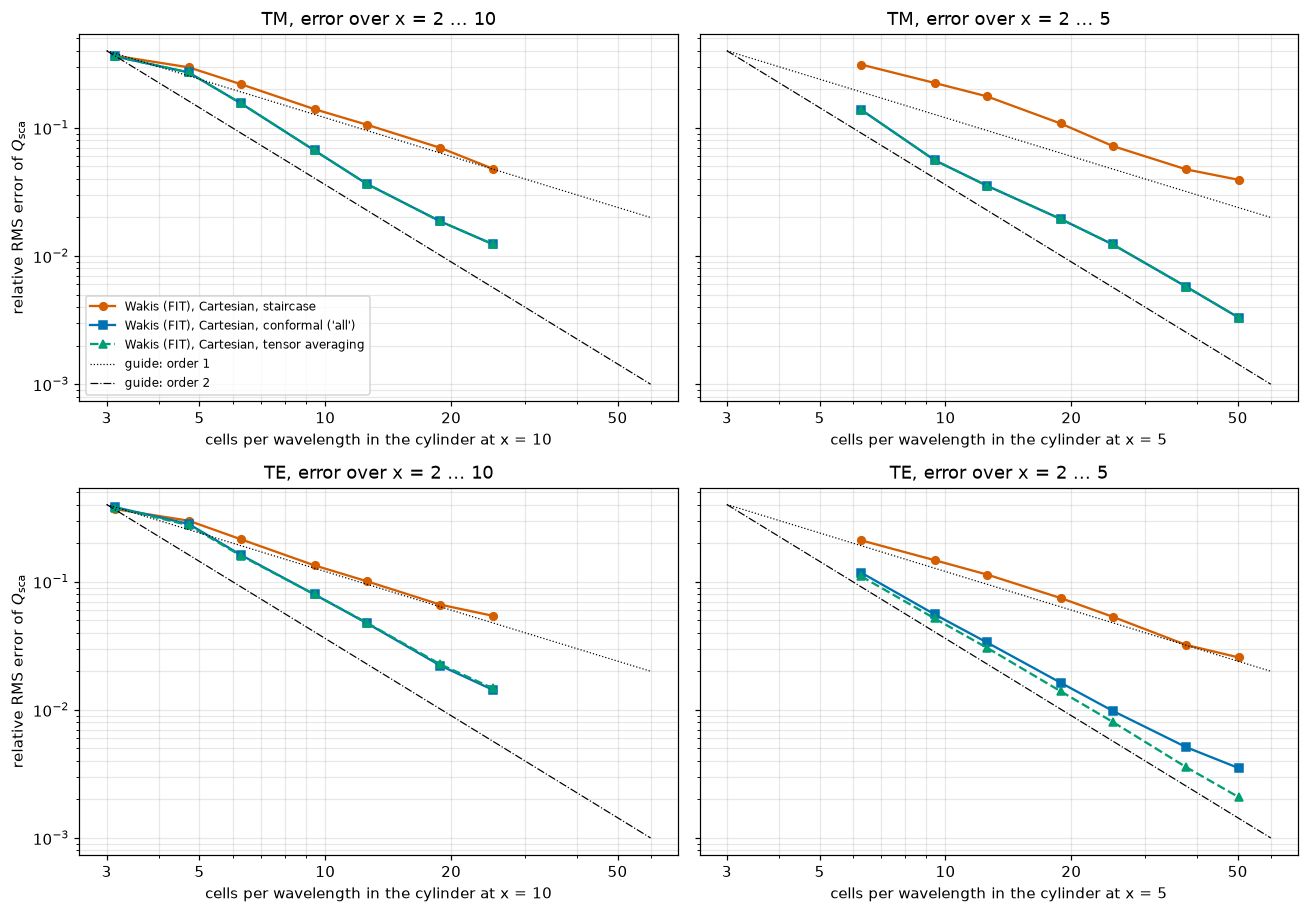

machine: GCP g2-standard-16 (cem-gpu): 10-40 cells/um on shared CPU cores, 60-80 cells/um on an NVIDIA L4 (4 runs at a time); 600 fs window


In [17]:
def load_convergence():
    path = DATA_DIR / "convergence.json"
    if path.exists():
        return json.loads(path.read_text())
    try:  # e.g. on Colab, where only the notebook was downloaded
        import urllib.request

        url = ("https://raw.githubusercontent.com/eshipton/Wakis/main/tutorials/"
               "03_diffraction_and_scattering/03-04_mie_cylinder/data/convergence.json")  # fmt: skip
        with urllib.request.urlopen(url, timeout=20) as f:
            return json.loads(f.read())
    except Exception as err:
        print("convergence data not available:", err)
        return None


def band_error(run, x_hi):
    """Relative RMS error of Q_sca over x = 2 ... x_hi, and cells per internal
    wavelength at x_hi."""
    x = np.array(run["x"])
    keep = x <= x_hi + 1e-9
    q, ref = np.array(run["q_sca"])[keep], np.array(run["q_ref"])[keep]
    dx = 1e-6 / run["resolution_per_um"]
    cpw = 2 * np.pi * A_CYL / x_hi / N_CYL / dx
    return cpw, np.sqrt(np.mean((q - ref) ** 2) / np.mean(ref**2))


study = load_convergence()
if study:
    names = {m: f"{wv.SIM_LABEL}, {st['label']}" for m, st in wv.MESH_STYLES.items()}
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.4), sharey="row")
    for i, pol in enumerate(("TM", "TE")):
        for j, x_hi in enumerate((X_MAX, 5.0)):
            ax = axes[i, j]
            for model, st in wv.MESH_STYLES.items():
                rs = sorted((r for r in study["runs"]
                             if r["conformal"] == model and r["pol"] == pol),
                            key=lambda r: r["resolution_per_um"])  # fmt: skip
                if not rs:
                    continue
                pts = np.array([band_error(r, x_hi) for r in rs])
                ax.loglog(pts[:, 0], pts[:, 1], marker=st["marker"], color=st["color"],
                          label=names[model], ms=5,
                          ls="--" if model == "tensor" else "-")  # fmt: skip
            cpw = np.array([3.0, 60.0])
            for order, ls in ((1, ":"), (2, "-.")):
                ax.loglog(cpw, 0.4 * (cpw / cpw[0]) ** (-order), "k" + ls, lw=0.8,
                          label=f"guide: order {order}")  # fmt: skip
            ax.set_xticks([3, 5, 10, 20, 50])
            ax.xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
            ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
            ax.set(title=f"{pol}, error over x = 2 ... {x_hi:g}",
                   xlabel=f"cells per wavelength in the cylinder at x = {x_hi:g}")  # fmt: skip
            ax.grid(True, which="both", alpha=0.3)
        axes[i, 0].set_ylabel(r"relative RMS error of $Q_\mathrm{sca}$")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    savefig(fig, "convergence.png")
    plt.show()
    print("machine:", study.get("machine", ""))

## 11. Triangular mesh: FIT beyond the Cartesian grid

FIT does not need a Cartesian grid. Its unknowns are integrals of the
fields over the edges and faces of *any* primal mesh and of its dual mesh,
and Maxwell's equations become exact incidence relations between them; only
the material (Hodge) operators are approximations. On a triangular mesh the
natural dual is the **Voronoi** diagram: the dual nodes are the triangles'
circumcentres and every dual edge crosses its primal edge at a right angle,
so the Hodge operator stays diagonal. A Delaunay mesh can place its nodes
*on* the circle, so there is no staircase and no averaging model at all
(`wakis.unstructured`, truly 2D: three field components per node and edge).

**Build the mesh.** `disk_mesh` puts nodes on a ring at the cylinder
radius (slightly enlarged so that the polygon has exactly the area of the
circle) and on a hexagonal lattice elsewhere, then triangulates. The outer
ring, at the radius where the Cartesian CPML starts, carries a first-order
absorbing boundary condition. Below: the triangles (blue inside the
cylinder), their Voronoi dual (orange) and the true circle (black), at the
same edge length $h$ as the Cartesian run above.

triangle mesh: 95561 nodes, 285662 edges, 190102 triangles (h = 17 nm)


/home/erikshipton/tut01/wakis/visualize.py:953: PyVistaDeprecationWarning: `extract_geometry` is deprecated. Use `extract_surface(algorithm=None)` instead.
  sub = tri.extract_cells(np.flatnonzero(tags == tag)).extract_geometry()


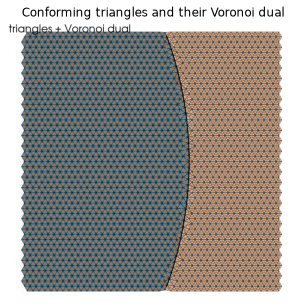

In [18]:
from matplotlib.tri import Triangulation
from scipy.sparse import csr_matrix

from wakis.cylinder_harmonics import (
    circle_points,
    fit_harmonics,
    mie_coefficients_from_fit,
    project_harmonics,
    q_sca_from_coefficients,
)
from wakis.unstructured import UnstructuredFIT2D
from wakis.unstructured.meshers import disk_mesh

R_OUT = 2.7e-6  # absorbing boundary (= start of the Cartesian CPML) [m]
H_TRI = layout(RESOLUTION)["dx"]  # same edge length as the Cartesian cells
tri_mesh = disk_mesh([A_CYL, R_OUT], H_TRI)
print(f"triangle mesh: {tri_mesh.n_nodes} nodes, {tri_mesh.n_edges} edges, "
      f"{tri_mesh.n_cells} triangles (h = {H_TRI * 1e9:.0f} nm)")  # fmt: skip
pl = wv.plot_triangle_mesh(
    tri_mesh, window=(0.55e-6, 1.25e-6, -0.35e-6, 0.35e-6), surfaces=[cylinder],
    tag_colors={0: "#56B4E9", 1: "#F0F0F0"}, title="triangles + Voronoi dual",
)  # fmt: skip
wv.save_plotter(pl, str(FIG_DIR / "mesh_triangles.png"))
show_png(FIG_DIR / "mesh_triangles.png", "Conforming triangles and their Voronoi dual")

**Run it.** The triangle solver uses a *scattered-field* plane wave
(`add_plane_wave`): the analytic incident wave enters only through the
constitutive relation inside the cylinder, so there is no TF/SF box. With
no flux box either, $Q_\mathrm{sca}$ is extracted from the scattered field
on three circles (r = 1.9, 2.2, 2.5 µm): it is projected on the angular
harmonics $e^{in\theta}$, each harmonic is fitted as outgoing plus incoming
Hankel waves, and the incoming part (reflections of the absorbing
boundary, 3-6 % for this first-order ABC) is de-embedded through the
cylinder's scattering matrix (`wakis.cylinder_harmonics`). The same
extraction applied to the Cartesian runs agrees with their flux boxes to
0.3 % RMS at 20 cells per internal wavelength.

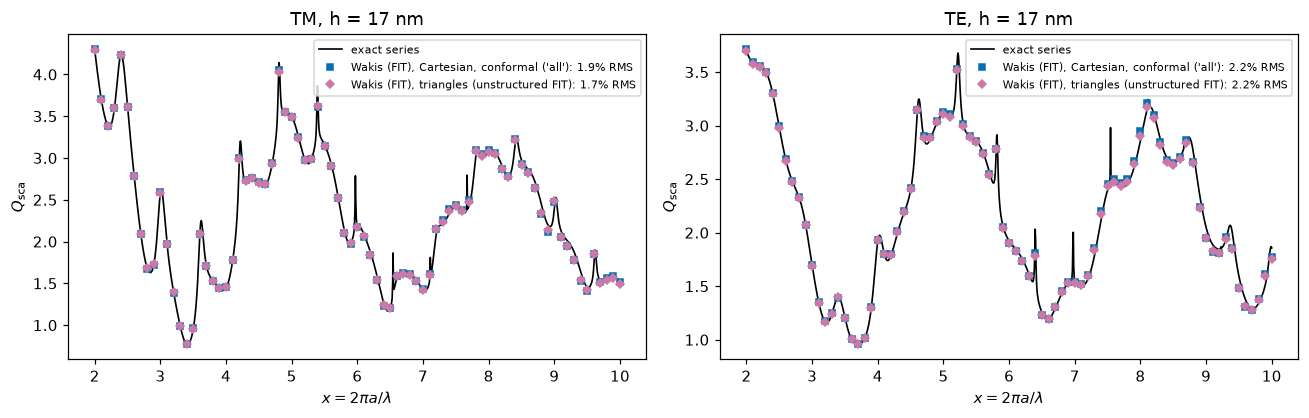

TM: Cartesian 214 k unknowns x 37569 steps = 8.03e+09;  triangles 381 k unknowns x 20459 steps = 7.80e+09
TE: Cartesian 214 k unknowns x 37569 steps = 8.03e+09;  triangles 381 k unknowns x 20459 steps = 7.80e+09


In [19]:
def interpolation_matrix(mesh, points):
    """Sparse linear (barycentric) interpolation from mesh nodes to points."""
    nodes, cells = mesh.nodes, mesh.cells
    tri = Triangulation(nodes[:, 0], nodes[:, 1], cells)
    cell = tri.get_trifinder()(points[:, 0], points[:, 1])
    if np.any(cell < 0):
        raise ValueError("a sample point lies outside the mesh")
    V = nodes[cells[cell]]  # (n_points, 3, 2)
    T = np.stack([V[:, 1] - V[:, 0], V[:, 2] - V[:, 0]], axis=2)
    lam12 = np.linalg.solve(T, (points - V[:, 0])[..., None])[..., 0]
    lam = np.column_stack([1 - lam12.sum(1), lam12])
    rows = np.repeat(np.arange(len(points)), 3)
    return csr_matrix((lam.ravel(), (rows, cells[cell].ravel())),
                      shape=(len(points), mesh.n_nodes))  # fmt: skip


def run_triangles(h, pol, hodge="voronoi", radii=(1.9e-6, 2.2e-6, 2.5e-6),
                  n_points=256, n_harm=30):  # fmt: skip
    """Triangle FIT run with harmonic Q_sca extraction; returns a dict."""
    t0 = time.time()
    mesh = disk_mesh([A_CYL, R_OUT], h)
    solver = UnstructuredFIT2D(mesh, {0: [N_CYL**2, 1.0]}, polarization=pol,
                               bc="abc", hodge=hodge, cfl=0.95)  # fmt: skip
    solver.add_plane_wave(GaussianSource(frequency=F_CENTER, fwidth=F_WIDTH))
    pts = np.vstack([circle_points(r, n_points)[0] for r in radii])
    P = interpolation_matrix(mesh, pts)[:, solver.free]
    dt = solver.dt
    n_steps = int(T_RUN / dt)
    shift = 0.0 if pol == "TM" else -0.5 * dt  # H_z lives at half steps
    times = (np.arange(n_steps) + 1) * dt + shift
    acc = np.zeros((FREQS.size, len(pts)), complex)
    t1 = time.time()
    for n in range(n_steps):
        solver.one_step()
        acc += np.outer(np.exp(-2j * np.pi * FREQS * times[n]), P @ solver.u) * dt
    t_run = time.time() - t1
    u_inc0 = np.ravel(solver.incident_field(np.zeros((1, 2)), times))
    u0 = (np.exp(-2j * np.pi * np.outer(FREQS, times)) @ u_inc0) * dt
    F = project_harmonics(acc.reshape(FREQS.size, len(radii), n_points), n_harm)
    alpha, gamma, _ = fit_harmonics(F, 2 * np.pi * FREQS / c0, np.array(radii), n_harm)
    c_n = mie_coefficients_from_fit(alpha, gamma, np.conj(u0), n_harm)
    n = np.arange(-n_harm, n_harm + 1)
    n_stop = np.floor(X_SIM + 4 * X_SIM ** (1 / 3) + 2)[:, None] + 4
    q_sca = q_sca_from_coefficients(
        np.where(np.abs(n)[None, :] <= n_stop, c_n, 0), X_SIM
    )
    return dict(q_sca=q_sca, steps=n_steps, unknowns=int(solver.free.size + mesh.n_edges),
                setup_s=t1 - t0, run_s=t_run, mesh=mesh)  # fmt: skip


tri_runs = {pol: run_triangles(H_TRI, pol) for pol in ("TM", "TE")}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, (pol, col) in zip(axes, (("TM", "#D55E00"), ("TE", "#0072B2"))):
    ref = cylinder_efficiencies(N_CYL, X_SIM, pol)[1]
    ax.plot(x_fine, cylinder_efficiencies(N_CYL, x_fine, pol)[1], "-", color="k",
            lw=1.1, label=wv.THEORY_LABEL)  # fmt: skip
    for q, st, name in (
        (runs[pol]["q_sca"], wv.MESH_STYLES[CONFORMAL], "Cartesian"),
        (tri_runs[pol]["q_sca"], wv.MESH_STYLES["triangles"], "triangles"),
    ):
        err = np.sqrt(np.mean((q - ref) ** 2) / np.mean(ref**2))
        ax.plot(X_SIM, q, ls="none", marker=st["marker"], ms=3.5, color=st["color"],
                label=f"{wv.SIM_LABEL}, {st['label']}: {err:.1%} RMS")  # fmt: skip
    ax.set(title=f"{pol}, h = {H_TRI * 1e9:.0f} nm", xlabel=r"$x = 2\pi a/\lambda$",
           ylabel=r"$Q_\mathrm{sca}$")  # fmt: skip
    ax.legend(fontsize=7.5)
fig.tight_layout()
savefig(fig, "qsca_triangles_vs_cartesian.png")
plt.show()
for pol in ("TM", "TE"):
    cart, tri = summary(runs[pol]), tri_runs[pol]
    n_cart = 3 * (cart["cells"] // NZ)  # 2D unknowns: E_z, H_x, H_y (TM) per cell
    print(f"{pol}: Cartesian {n_cart / 1e3:.0f} k unknowns x {cart['steps']} steps "
          f"= {n_cart * cart['steps']:.2e};  triangles {tri['unknowns'] / 1e3:.0f} k "
          f"unknowns x {tri['steps']} steps = {tri['unknowns'] * tri['steps']:.2e}")  # fmt: skip

The work printed above is *not* an equal-cost comparison: this tutorial's
Cartesian runs use the 3D solver on a 4-cell periodic slab, whose time
step is set by the 3D stability limit with $\Delta z = \Delta x$ and the
default Courant number 0.5, about twice as many steps as a 2D code needs.
The study below runs every arm at 0.95 of its own stability limit (and a
slab with $\Delta z = 10h$), and counts 3 unknowns per Cartesian cell.

**The full comparison** (`studies/mie-cylinder-mesh/`, 48 runs from 10 to
40 cells per internal wavelength, 1000 fs windows, the same harmonic
extraction for every arm). Below: the meshes at the interface, and the
error against cells per wavelength, unknowns and work (unknowns x steps).

* **Equal accuracy at equal h.** Conformal Cartesian and conforming
  triangles are both second order and within ~10 % of each other: 0.62 %
  vs 0.71 % RMS (TM) and 0.64 % vs 0.63 % (TE) at 40 cells per internal
  wavelength.
* **Conformal Cartesian is ~1.45x cheaper at equal error.** At the same h
  the hexagonal triangle lattice has ~14 % more unknowns (three edges per
  node) and a 21 % smaller time step (CFL of the smallest dual edges):
  1.25e11 vs 0.86e11 unknowns x steps at 40 cells per wavelength.
* **The staircase is far behind**: 3.9 % (TM) and 6.2 % (TE) at the
  same resolution, converging at first order or worse.

**Why?** For a smooth, moderate-contrast interface ($n = 2$, radius 1 µm,
many cells across), subpixel averaging already captures the interface to
second order, and over $x \le 10$ every second-order arm is limited by the
*bulk* numerical dispersion at the short-wavelength end, not by the
interface. The geometric advantage of a conforming mesh is real but not
needed here. Triangles should win where averaging fails: sharp corners and
wedges (field singularities), thin gaps and shells below a cell, metals and
plasmonic interfaces (sign-changing permittivity, where averaging breaks
down), and multiscale geometry that needs local refinement instead of a
uniformly fine grid. Note also that the triangle runs use a first-order
absorbing boundary that reflects 3-6 %: the de-embedding removes its
first-order effect, a PML for the unstructured solver is on the roadmap.

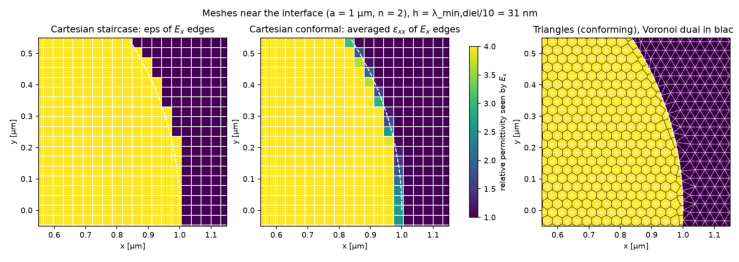

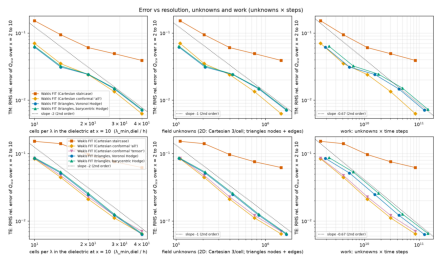

In [20]:
study_root = HERE.parents[0].parent / "studies" / "mie-cylinder-mesh" / "figures"
for name, local, size in (
    ("a_meshes", "tri_study_a_meshes.png", (13, 4.5)),
    ("d_convergence", "tri_study_d_convergence.png", (13, 4.5)),
):
    png = study_root / f"{name}.png"
    png = png if png.exists() else FIG_DIR / local
    if png.exists():
        show_png(png, figsize=size)

## 12. Limits and failure modes

* **Resolution inside the scatterer.** At $x = 10$ the wavelength inside
  the $n = 2$ cylinder is 0.314 µm. Below ~10 cells per internal
  wavelength the numerical phase-velocity error shifts the resonances,
  visible as shifted peaks in $\Delta Q$.
* **Staircasing** enlarges the effective radius by about half a cell
  (section 4): first-order convergence. Conformal
  averaging fixes the interface position; for TE (E crossing the curved
  interface) only the full tensor averaging restores second order.
* **Truncated ring-down.** High-order resonances ring for many periods.
  If the run stops before the fields have decayed, the DFT is windowed and
  $Q(x)$ gets ripples and broadened peaks. The energy criterion and the
  maximum window `T_RUN` control this; check the "energy decayed" flag.
  Measured here: at 20 cells/µm, $Q_\mathrm{sca}$ from a 400 fs window
  differs from a 1600 fs window by 0.6 % RMS (max 0.06 at the sharpest
  peak); the tutorial and the study use 600 fs, so this floor lies below
  the discretization errors shown in section 10.
* **Box placement.** The TF/SF faces must not touch the scatterer or the
  CPML; the scattered flux box must lie at least one node outside the
  TF/SF surface and the inner box one node inside it. A face on the TF/SF
  surface or cutting a staircased object spoils the net flux.
* **TF/SF limitations** of the current implementation: axis-aligned
  incidence, homogeneous lossless background at the box surface, no MPI.
  Oblique incidence and layered backgrounds (a wire on a substrate) need a
  different incident-field solver.
* **2D means infinitely long.** Real wires are finite; end effects and the
  3D near field are outside this model (Tutorial 3.5 does the sphere).
* **What agreement does not prove.** $Q_\mathrm{sca}$ checks the power
  balance, not the phase of the near field; the field maps and the
  $Q_\mathrm{abs} = 0$ check test other parts of the pipeline.

## 13. Exercises

1. **Resonances.** Change the index to $n = 1.5$ and $n = 3.5$. How do the
   resonance widths change, and how many cells per internal wavelength do
   you need for 1 % RMS error? *Run `preflight` first.*
2. **Where is the error?** Plot $\Delta Q(x)$ for two resolutions. Is it
   concentrated at the resonances? Shift the simulated curve in $x$ to
   separate a phase-velocity (dispersion) error from an amplitude error.
3. **Equivalent currents by hand.** Rebuild the TF/SF box from
   `CurrentSource` and `MagneticCurrentSource` sheets on its faces with the
   analytic plane-wave phase, as in the companion Meep notebook
   (*Total-Field/Scattered-Field Technique with Meep FDTD*). Run the empty
   domain and measure the leakage through the scattered flux box against
   frequency. Which part comes from the half-cell E/H offset and which from
   numerical dispersion? (Compare with `studies/tfsf/tfsf_study.py`.)
4. **Two-run subtraction** (Oskooi & Johnson, sec. 4.3). Replace the TF/SF
   box by a plane source left of the cylinder, run with and without the
   cylinder, and subtract the DFT fields on the flux box. Compare accuracy
   and cost with TF/SF.
5. **Symmetry test.** Use `direction="+y"` with `polarization="x"` (TE)
   or `"z"` (TM). $Q_\mathrm{sca}$ must not change: how large is the
   difference on the grid, and how does it scale with resolution?
6. **Differential scattering width.** Record $E_z$ and $H$ on a circle (or
   the flux box) and project it to the far field with the 2D Green's
   function; compare $dC/d\theta = 2|T(\theta)|^2/(\pi k)$ from
   `wakis.analytic.cylinder_amplitude`.
7. **Where should triangles win?** Replace the cylinder by a square rod
   with sharp corners, a thin dielectric shell (thickness below one
   Cartesian cell), or a Drude-metal cylinder near its surface-plasmon
   resonance. Compare conformal Cartesian and `disk_mesh`-style conforming
   triangles at equal work (unknowns x steps), not equal h. Which arm wins,
   and does the answer change with local mesh refinement near the corner?
8. **Towards plasmonics.** Make the cylinder a Drude metal
   (`wakis.dispersive`), use the inner flux box for $Q_\mathrm{abs}$, and
   compare with `cylinder_efficiencies` at complex $m$.

## 14. References

1. D. E. Merewether, R. Fisher and F. W. Smith, "On implementing a numeric
   Huygen's source scheme in a finite difference program to illuminate
   scattering bodies," *IEEE Trans. Nucl. Sci.* **27**(6), 1829-1833
   (1980).
2. A. Taflove and S. C. Hagness, *Computational Electrodynamics: The
   Finite-Difference Time-Domain Method*, 3rd ed. (Artech House, 2005).
3. A. Oskooi and S. G. Johnson, "Electromagnetic wave source conditions,"
   ch. 4 in A. Taflove, A. Oskooi and S. G. Johnson (eds.), *Advances in
   FDTD Computational Electrodynamics: Photonics and Nanotechnology*
   (Artech House, 2013); arXiv:1301.5366.
4. C. F. Bohren and D. R. Huffman, *Absorption and Scattering of Light by
   Small Particles* (Wiley, 1983), ch. 8 (infinite cylinder).
5. C. Kottke, A. Farjadpour and S. G. Johnson, "Perturbation theory for
   anisotropic dielectric interfaces, and application to subpixel
   smoothing of discretized numerical methods," *Phys. Rev. E* **77**,
   036611 (2008).
6. Meep tutorial "Mie scattering of a lossless dielectric sphere"
   (https://meep.readthedocs.io), whose physical parameters (n = 2,
   radius 1 µm, x = 2-10) this series reuses with an independent code.